In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Set plotting aesthetics
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Data Cleaning & Pipeline Preprocessing

In [11]:
# Load datasets
apps_df = pd.read_csv('googleplaystore.csv')
reviews_df = pd.read_csv('googleplaystore_user_reviews.csv')

print(f"Initial shapes -> Apps: {apps_df.shape}, Reviews: {reviews_df.shape}")

# 1. Remove duplicates
apps_df.drop_duplicates(subset='App', keep='first', inplace=True)

# 2. Clean Installs column
apps_df['Installs'] = apps_df['Installs'].str.replace('+', '', regex=False)
apps_df['Installs'] = apps_df['Installs'].str.replace(',', '', regex=False)
apps_df['Installs'] = pd.to_numeric(apps_df['Installs'], errors='coerce')

# 3. Clean Price column
apps_df['Price'] = apps_df['Price'].str.replace('$', '', regex=False)
apps_df['Price'] = pd.to_numeric(apps_df['Price'], errors='coerce')

# 4. Clean Size column (Convert Megabytes to numeric float, handle 'Varies with device')
def clean_size(val):
    if pd.isna(val) or val == 'Varies with device':
        return np.nan
    val = str(val).upper()
    if 'M' in val:
        return float(val.replace('M', ''))
    if 'K' in val:
        return float(val.replace('K', '')) / 1024
    return float(val)

apps_df['Size_MB'] = apps_df['Size'].apply(clean_size)
apps_df['Size_MB'] = apps_df['Size_MB'].fillna(apps_df['Size_MB'].median())

# 5. Handle missing Ratings by category median
apps_df['Rating'] = apps_df.groupby('Category')['Rating'].transform(lambda x: x.fillna(x.median()))

print(f"Cleaned shapes -> Apps: {apps_df.shape}")
apps_df.head()

Initial shapes -> Apps: (1020, 9), Reviews: (500, 2)
Cleaned shapes -> Apps: (1000, 10)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Size_MB
0,App_0,GAME,4.288851,417226,Varies with device,100000,Free,0.00,Everyone 10+,19.0
1,App_1,SPORTS,3.532328,111042,19M,500000,Free,0.00,Everyone 10+,19.0
2,App_2,MEDICAL,4.193815,206950,4.5M,5000,Free,0.00,Teen,4.5
3,App_3,BUSINESS,4.505293,304758,19M,5000,Free,0.00,Mature 17+,19.0
4,App_4,FAMILY,4.479895,461562,4.5M,100000,Free,9.99,Everyone,4.5


## 3. Category & Saturated Markets Analysis

/tmp/ipykernel_1390/1968848633.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




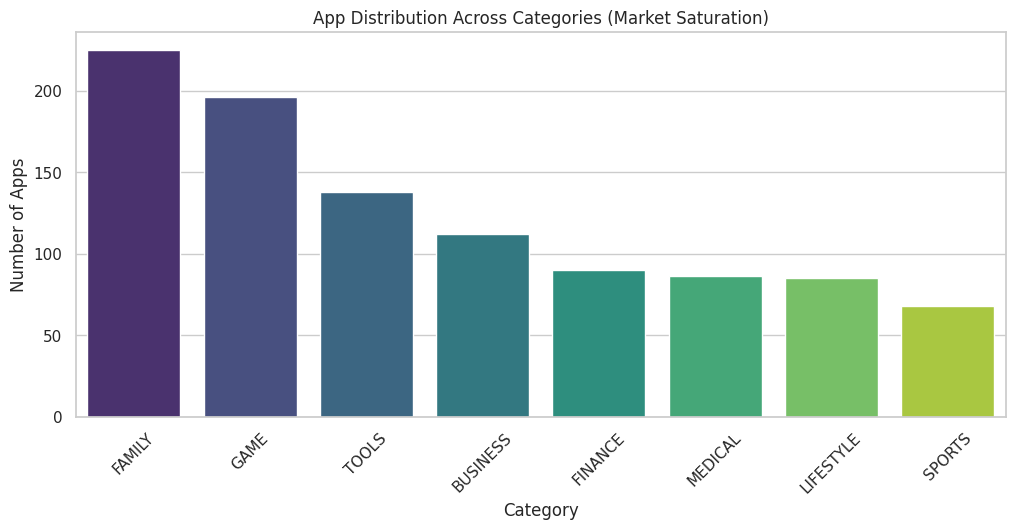

Top 3 Most Saturated Categories:
Category
FAMILY    225
GAME      196
TOOLS     138
Name: count, dtype: int64


In [12]:
category_counts = apps_df['Category'].value_counts()

plt.figure(figsize=(12, 5))
sns.barplot(x=category_counts.index, y=category_counts.values, palette='viridis')
plt.title('App Distribution Across Categories (Market Saturation)')
plt.xlabel('Category')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)
plt.show()

print("Top 3 Most Saturated Categories:")
print(category_counts.head(3))

## 4. Ratings Distribution Analysis

/tmp/ipykernel_1390/3239007187.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




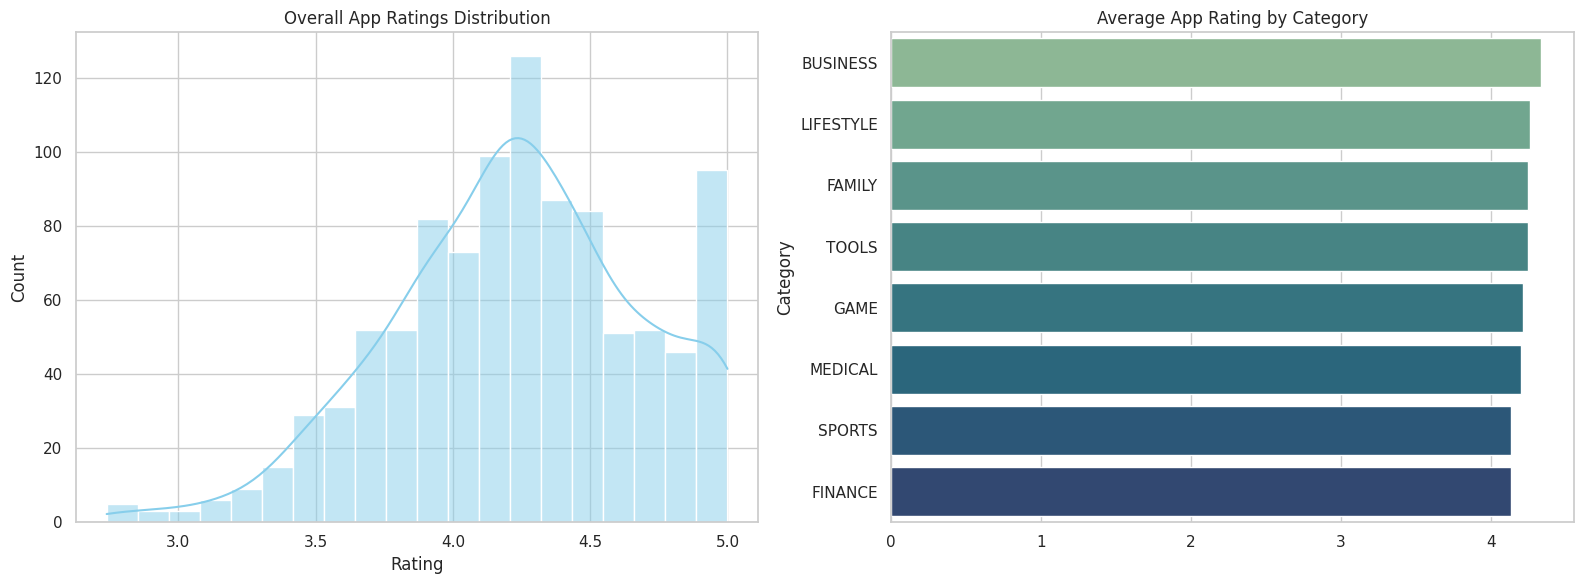

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall Distribution
sns.histplot(apps_df['Rating'], kde=True, ax=axes[0], color='skyblue', bins=20)
axes[0].set_title('Overall App Ratings Distribution')

# Average Rating by Category
avg_rating_cat = apps_df.groupby('Category')['Rating'].mean().sort_values(ascending=False)
sns.barplot(x=avg_rating_cat.values, y=avg_rating_cat.index, ax=axes[1], palette='crest')
axes[1].set_title('Average App Rating by Category')

plt.tight_layout()
plt.show()

## 5. App Size vs. Installs Correlation

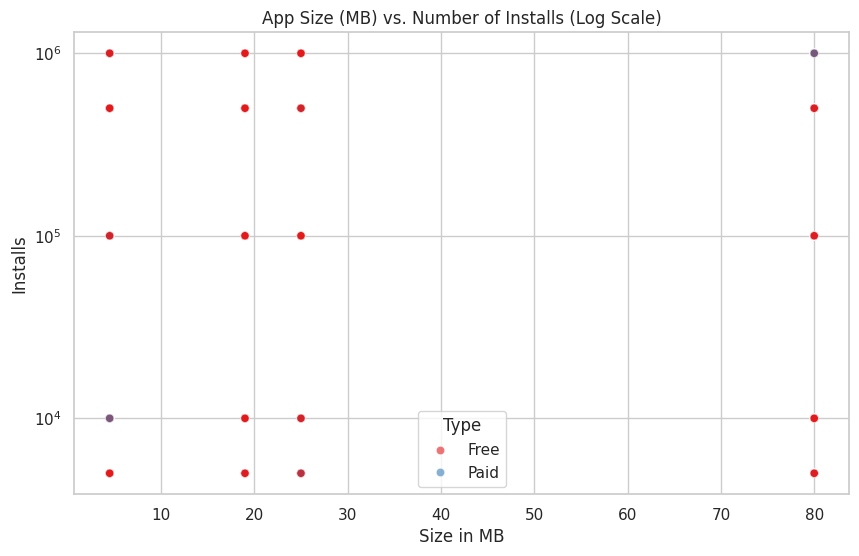

Pearson correlation between Size and Installs: -0.0474


In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=apps_df, x='Size_MB', y='Installs', hue='Type', alpha=0.6, palette='Set1')
plt.yscale('log')  # Log scale due to wide range of installs
plt.title('App Size (MB) vs. Number of Installs (Log Scale)')
plt.xlabel('Size in MB')
plt.ylabel('Installs')
plt.show()

corr = apps_df[['Size_MB', 'Installs']].corr().iloc[0, 1]
print(f"Pearson correlation between Size and Installs: {corr:.4f}")

## 6. Financial & Monetisation Models

/tmp/ipykernel_1390/3082939575.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




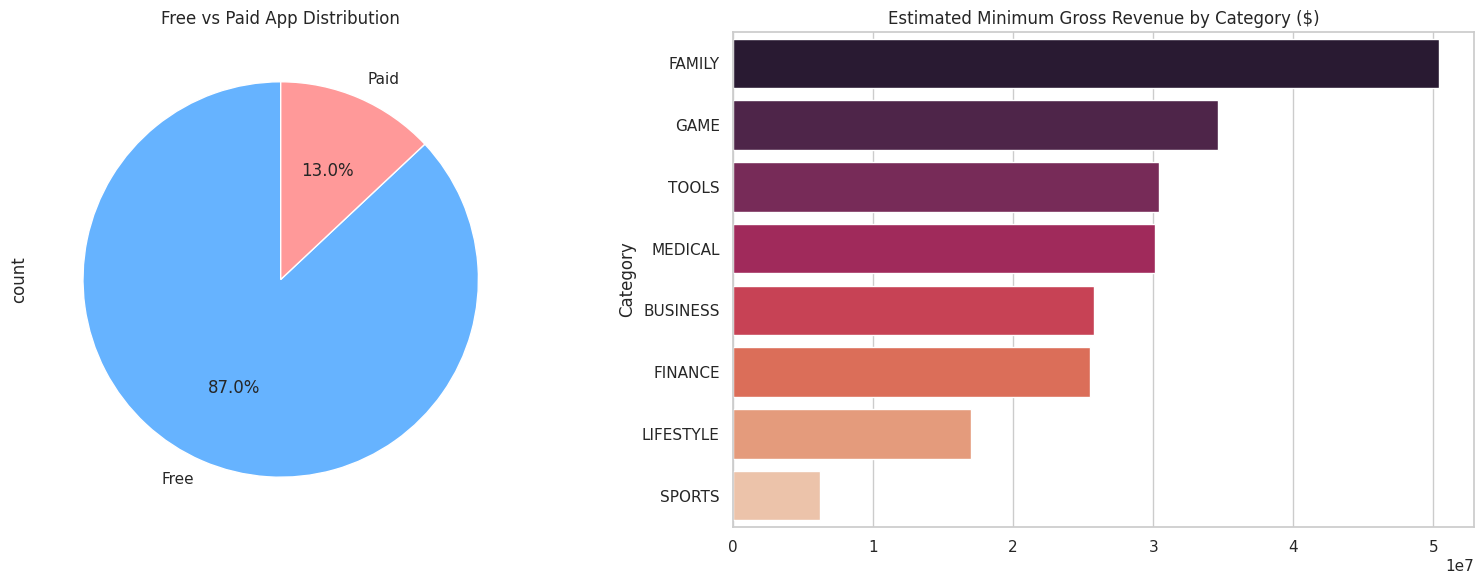

In [15]:
apps_df['Est_Revenue'] = apps_df['Installs'] * apps_df['Price']
rev_by_cat = apps_df.groupby('Category')['Est_Revenue'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pie Chart of Free vs Paid
apps_df['Type'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0], colors=['#66b3ff','#ff9999'], startangle=90)
axes[0].set_title('Free vs Paid App Distribution')

# Bar chart of revenue framework
sns.barplot(x=rev_by_cat.values, y=rev_by_cat.index, ax=axes[1], palette='rocket')
axes[1].set_title('Estimated Minimum Gross Revenue by Category ($)')

plt.tight_layout()
plt.show()

## 7. Sentiment Analysis on Reviews using VADER

In [16]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

def get_sentiment_label(text):
    if pd.isna(text):
        return 'Neutral'
    score = sia.polarity_scores(str(text))['compound']
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

reviews_df['Sentiment'] = reviews_df['Translated_Review'].apply(get_sentiment_label)

# Merge with apps dataset to get categories
merged_reviews = pd.merge(reviews_df, apps_df[['App', 'Category']], on='App', how='inner')

# Visualise sentiment breakout
sentiment_counts = merged_reviews['Sentiment'].value_counts()
print("Sentiment Distribution across sample:")
print(sentiment_counts)

Sentiment Distribution across sample:
Sentiment
Positive    283
Negative    217
Name: count, dtype: int64


## 8. Interactive Visualisation (Plotly)

In [17]:
# Interactive treemap showing Category size, average ratings and monetization type breakout
fig_plotly = px.treemap(
    apps_df,
    path=['Category', 'Type'],
    values='Installs',
    color='Rating',
    color_continuous_scale='RdYlGn',
    title='Interactive Breakdown of Market Volume & Ratings by Category/Type'
)
fig_plotly.show()